In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os
from PIL import Image

# Path to your dataset folder
dataset_path = "/content/drive/MyDrive/Mango Leaf Dataset/Raw Images"

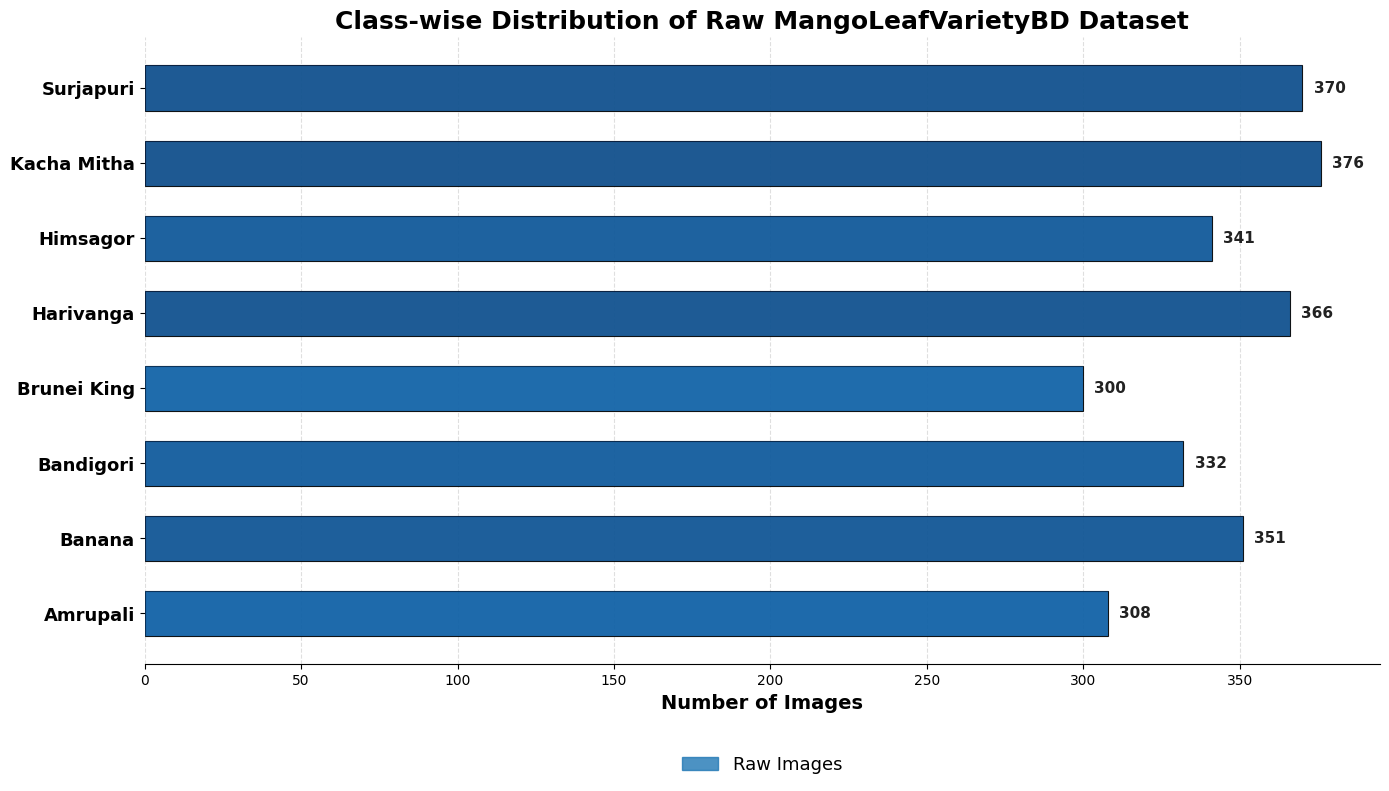

Professional Raw Dataset Distribution chart saved at: /content/drive/MyDrive/Mango Leaf Dataset/Raw Images/Raw_Dataset_Distribution33333.png


In [11]:
import os
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

save_chart = "/content/drive/MyDrive/Mango Leaf Dataset/Raw Images/Raw_Dataset_Distribution33333.png"

# Function to count images per class
def count_images(folder):
    counts = {}
    for cls in os.listdir(folder):
        cls_folder = os.path.join(folder, cls)
        if os.path.isdir(cls_folder):
            n = len([f for f in os.listdir(cls_folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
            counts[cls] = n
    return counts

# Count images
class_counts = count_images(dataset_path)

# Sort classes
classes = sorted(class_counts.keys())
values = [class_counts[c] for c in classes]

y = np.arange(len(classes))
height = 0.6

# Create figure with transparent background
fig, ax = plt.subplots(figsize=(14, 8), facecolor='white')

# Gradient horizontal bars
for i, (val, cls_y) in enumerate(zip(values, y)):
    ax.barh(
        cls_y, val, height=height,
        color='#1f77b4', edgecolor='black', linewidth=0.8, alpha=0.9
    )
    # Gradient effect (overlay)
    ax.barh(
        cls_y, val, height=height,
        color=plt.cm.Blues(0.3 + 0.7 * val / max(values)), alpha=0.5
    )

# Gridlines
ax.xaxis.grid(True, linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

# Labels and title
ax.set_yticks(y)
ax.set_yticklabels(classes, fontsize=13, fontweight='bold')
ax.set_xlabel('Number of Images', fontsize=14, fontweight='bold')
ax.set_title('Class-wise Distribution of Raw MangoLeafVarietyBD Dataset', fontsize=18, fontweight='bold')

# Annotate bars
for bar_val, cls_y in zip(values, y):
    ax.annotate(
        f'{bar_val}',
        xy=(bar_val, cls_y),
        xytext=(8, 0),
        textcoords="offset points",
        ha='left', va='center',
        fontsize=11, fontweight='bold',
        color='#222222'
    )

# Legend (even single dataset, for presentation look)
legend_patch = Rectangle((0,0),1,1, color='#1f77b4', alpha=0.8)
ax.legend([legend_patch], ['Raw Images'], fontsize=13, loc='upper center',
          bbox_to_anchor=(0.5, -0.12), ncol=1, frameon=False)

# Minimalistic spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.savefig(save_chart, dpi=300, bbox_inches='tight', transparent=False)
plt.show()

print(f"Professional Raw Dataset Distribution chart saved at: {save_chart}")
